# Final LAI Model Comparison

This reporting notebook compares the verified leakage-free test results for Random Forest, ResNet-18, and EfficientNet-B0. It loads saved metrics and predictions only; it does not retrain, tune, or modify any model artifacts.

All final comparisons use the clean split: 234 train, 51 validation, and 51 test images.

In [4]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_project_root():
    current = Path.cwd().resolve()
    for candidate in [current, current.parent, *current.parents]:
        if (candidate / 'results' / 'lai_rf_clean_metrics.json').exists():
            return candidate
    raise FileNotFoundError('Could not locate the pixels-to-water project root.')

project_root = find_project_root()
results_dir = project_root / 'results'
print(f'Project root: {project_root}')
print(f'Results directory: {results_dir}')

Project root: C:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water
Results directory: C:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water\results


## 1. Load and verify clean metrics

The filenames below are the clean-split artifacts. The legacy ResNet metrics file is intentionally not used.

In [2]:
metric_files = {
    'Random Forest': 'lai_rf_clean_metrics.json',
    'ResNet-18': 'lai_resnet18_clean_metrics.json',
    'EfficientNet-B0': 'lai_efficientnet_b0_clean_metrics.json',
}
expected_split = {'train_samples': 234, 'validation_samples': 51, 'test_samples': 51}
expected_integrity = {
    'missing_image_paths': 0,
    'invalid_targets': 0,
    'cross_split_identical_image_hashes': 0,
    'cross_split_duplicate_paths': 0,
}

metrics = {}
for model_name, filename in metric_files.items():
    path = results_dir / filename
    if not path.exists():
        raise FileNotFoundError(f'Missing clean metrics artifact: {path}')
    record = json.loads(path.read_text(encoding='utf-8'))
    for key, expected in expected_split.items():
        if record.get(key) != expected:
            raise AssertionError(f'{model_name}: {key}={record.get(key)!r}, expected {expected}')
    for key, expected in expected_integrity.items():
        if key in record and record[key] != expected:
            raise AssertionError(f'{model_name}: {key}={record[key]!r}, expected {expected}')
    for key in ('MAE', 'RMSE', 'R2'):
        if key not in record or not np.isfinite(record[key]):
            raise AssertionError(f'{model_name}: missing or invalid {key}')
    metrics[model_name] = record

metric_table = pd.DataFrame([
    {'Model': model_name, 'MAE': record['MAE'], 'RMSE': record['RMSE'], 'R2': record['R2']}
    for model_name, record in metrics.items()
])
print('Verified clean metric artifacts:')
display(metric_table.style.format({'MAE': '{:.9f}', 'RMSE': '{:.9f}', 'R2': '{:.9f}'}))

Verified clean metric artifacts:


,Model,MAE,RMSE,R2
0,Random Forest,0.006192920,0.009753515,0.865564843
1,ResNet-18,0.096753566,0.120569790,-19.543174905
2,EfficientNet-B0,0.074103718,0.087935380,-9.927425230


## 2. Report-ready metric comparisons

Each metric has its own figure. MAE and RMSE are sorted lower-is-better; R² is sorted higher-is-better. The axes include zero so the bar lengths are not visually misleading.

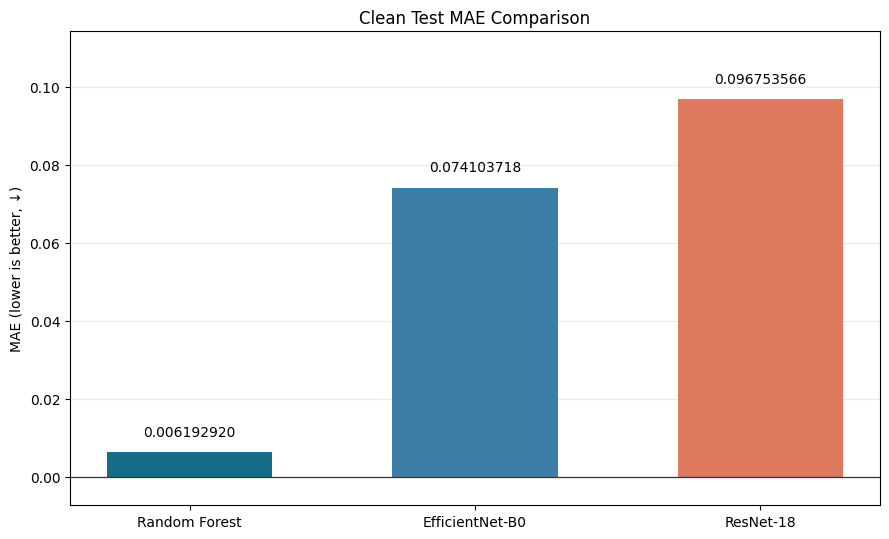

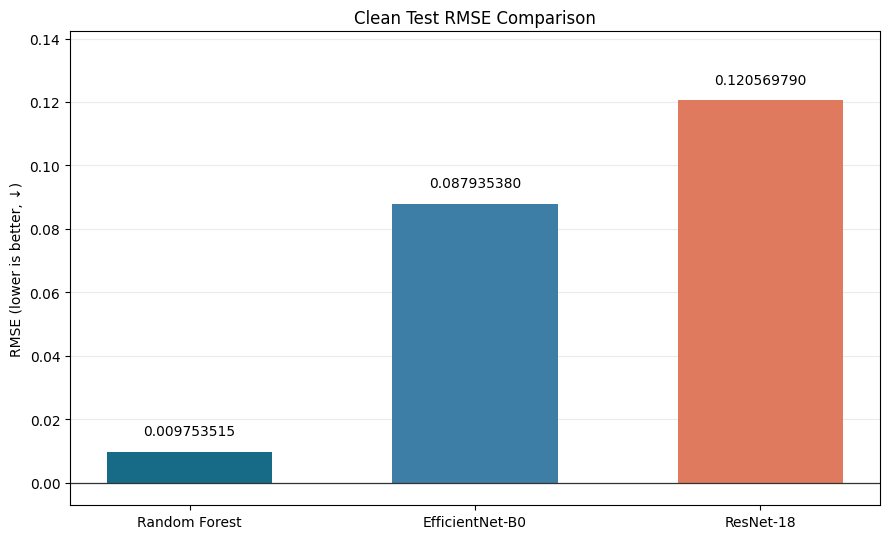

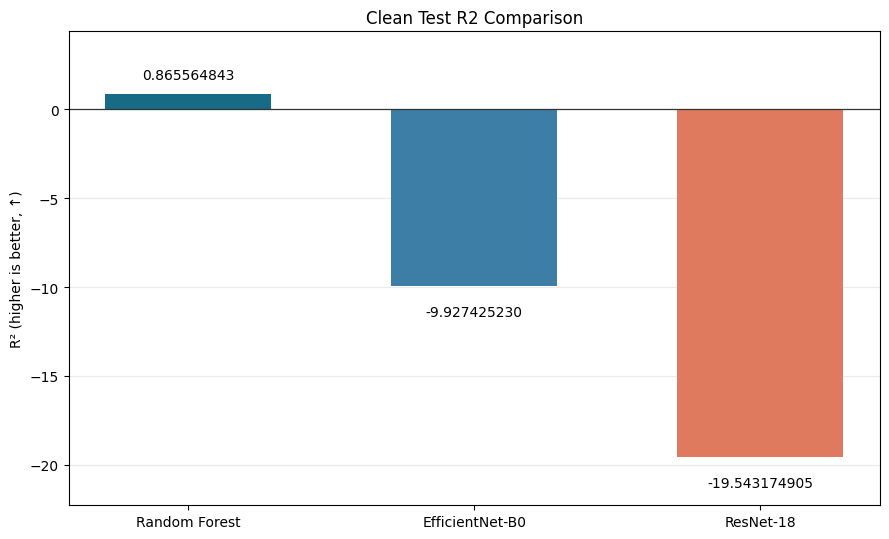

In [13]:
plot_specs = [
    ('MAE', 'MAE (lower is better, ↓)', 'lai_model_comparison_mae.png', True),
    ('RMSE', 'RMSE (lower is better, ↓)', 'lai_model_comparison_rmse.png', True),
    ('R2', 'R² (higher is better, ↑)', 'lai_model_comparison_r2.png', False),
]

for metric_name, axis_label, output_name, lower_is_better in plot_specs:
    ordered = metric_table.sort_values(metric_name, ascending=lower_is_better)
    figure, axis = plt.subplots(figsize=(9, 5.5))
    colors = ['#176b87' if model == 'Random Forest' else '#e07a5f' if model == 'ResNet-18' else '#3d7ea6' for model in ordered['Model']]
    bars = axis.bar(ordered['Model'], ordered[metric_name], color=colors, width=0.58)
    axis.axhline(0, color='#333333', linewidth=0.9)
    axis.set_ylabel(axis_label)
    axis.set_title(f'Clean Test {metric_name} Comparison')
    axis.grid(axis='y', alpha=0.25)
    axis.set_axisbelow(True)
    value_range = max(abs(float(ordered[metric_name].min())), abs(float(ordered[metric_name].max())), 0.001)
    axis.set_ylim(min(0, float(ordered[metric_name].min()) - value_range * 0.14), float(ordered[metric_name].max()) + value_range * 0.18)
    for bar, value in zip(bars, ordered[metric_name]):
        offset = value_range * 0.035 if value >= 0 else -value_range * 0.055
        vertical_alignment = 'bottom' if value >= 0 else 'top'
        axis.text(bar.get_x() + bar.get_width() / 2, value + offset, f'{value:.9f}', ha='center', va=vertical_alignment, fontsize=10)
    figure.tight_layout()
    figure.savefig(results_dir / output_name, dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(figure)

## 3. Align clean predictions by image path

The RF artifact calls its path column `image`; the two CNN artifacts call it `image_path`. The in-memory normalization below preserves every path and prediction while providing one comparison key.

In [5]:
prediction_files = {
    'Random Forest': 'lai_rf_clean_predictions.csv',
    'ResNet-18': 'lai_resnet18_clean_predictions.csv',
    'EfficientNet-B0': 'lai_efficientnet_b0_clean_predictions.csv',
}
required_columns = {'image_path', 'actual_LAI', 'predicted_LAI'}
predictions = {}
for model_name, filename in prediction_files.items():
    frame = pd.read_csv(results_dir / filename)
    if 'image_path' not in frame.columns and 'image' in frame.columns:
        frame = frame.rename(columns={'image': 'image_path'})
    if not required_columns.issubset(frame.columns):
        raise AssertionError(f'{model_name}: columns are {list(frame.columns)}')
    frame = frame[['image_path', 'actual_LAI', 'predicted_LAI']].copy()
    frame['image_path'] = frame['image_path'].astype(str)
    path_parts = frame['image_path'].map(Path)
    if model_name == 'Random Forest':
        frame['alignment_key'] = path_parts.map(
            lambda path: ('Indoor/' if path.stem.upper().startswith('IN_') else 'Outdoor/') + path.name[(3 if path.stem.upper().startswith('IN_') else 4):]
        )
    else:
        frame['alignment_key'] = path_parts.map(lambda path: '/'.join(path.parts[-2:]))
    if frame['alignment_key'].duplicated().any():
        raise AssertionError(f'{model_name}: duplicate aligned image paths found')
    if len(frame) != 51:
        raise AssertionError(f'{model_name}: expected 51 test predictions, found {len(frame)}')
    predictions[model_name] = frame

common_paths = set.intersection(*(set(frame['alignment_key']) for frame in predictions.values()))
if len(common_paths) != 51:
    raise AssertionError(f'Expected 51 shared clean test image paths, found {len(common_paths)}')

aligned = None
for model_name, frame in predictions.items():
    current = frame.rename(columns={'actual_LAI': 'actual_LAI_' + model_name, 'predicted_LAI': 'predicted_LAI_' + model_name})
    aligned = current if aligned is None else aligned.merge(current, on='alignment_key', how='inner', validate='one_to_one')
aligned = aligned.sort_values('alignment_key').reset_index(drop=True)
actual_columns = [column for column in aligned.columns if column.startswith('actual_LAI_')]
if not np.allclose(aligned[actual_columns].to_numpy(), aligned[actual_columns[0]].to_numpy()[:, None], rtol=0, atol=1e-8):
    raise AssertionError('Actual LAI values are not aligned across model prediction files.')
print(f'Aligned prediction rows: {len(aligned)}')
display(aligned.head())

Aligned prediction rows: 51


,image_path_x,actual_LAI_Random Forest,predicted_LAI_Random Forest,alignment_key,image_path_y,actual_LAI_ResNet-18,predicted_LAI_ResNet-18,image_path,actual_LAI_EfficientNet-B0,predicted_LAI_EfficientNet-B0
0,IN_DAG0202.jpg,0.000897,0.004510,Indoor/DAG0202.jpg,../DatasetLAI/Raw Images/Indoor/DAG0202.jpg,0.000897,-0.117902,../DatasetLAI/Raw Images/Indoor/DAG0202.jpg,0.000897,0.025928
1,IN_DAG0803.jpg,0.003951,0.005270,Indoor/DAG0803.jpg,../DatasetLAI/Raw Images/Indoor/DAG0803.jpg,0.003951,-0.110684,../DatasetLAI/Raw Images/Indoor/DAG0803.jpg,0.003951,0.023560
2,IN_DAG1104.jpg,0.010754,0.008861,Indoor/DAG1104.jpg,../DatasetLAI/Raw Images/Indoor/DAG1104.jpg,0.010754,-0.132797,../DatasetLAI/Raw Images/Indoor/DAG1104.jpg,0.010754,-0.017716
3,IN_DAG1202.jpg,0.019190,0.027204,Indoor/DAG1202.jpg,../DatasetLAI/Raw Images/Indoor/DAG1202.jpg,0.019190,-0.057829,../DatasetLAI/Raw Images/Indoor/DAG1202.jpg,0.019190,0.212772
4,IN_DAG1603.jpg,0.030272,0.040438,Indoor/DAG1603.jpg,../DatasetLAI/Raw Images/Indoor/DAG1603.jpg,0.030272,-0.334434,../DatasetLAI/Raw Images/Indoor/DAG1603.jpg,0.030272,-0.053889


## 4. Actual versus predicted LAI

The three panels use the same aligned clean test images and the same x/y limits. The dashed diagonal marks perfect prediction.

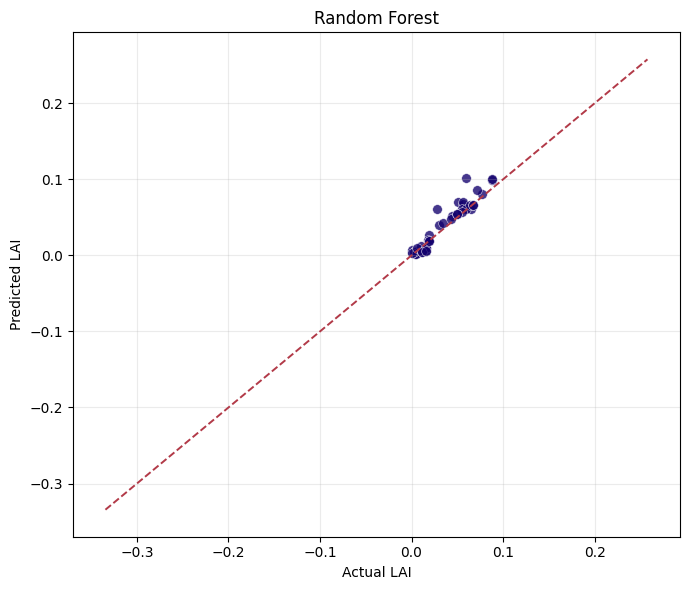

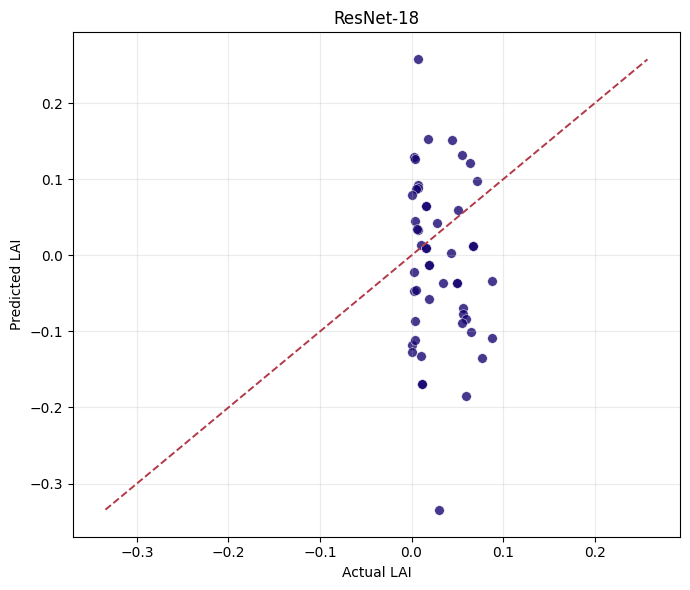

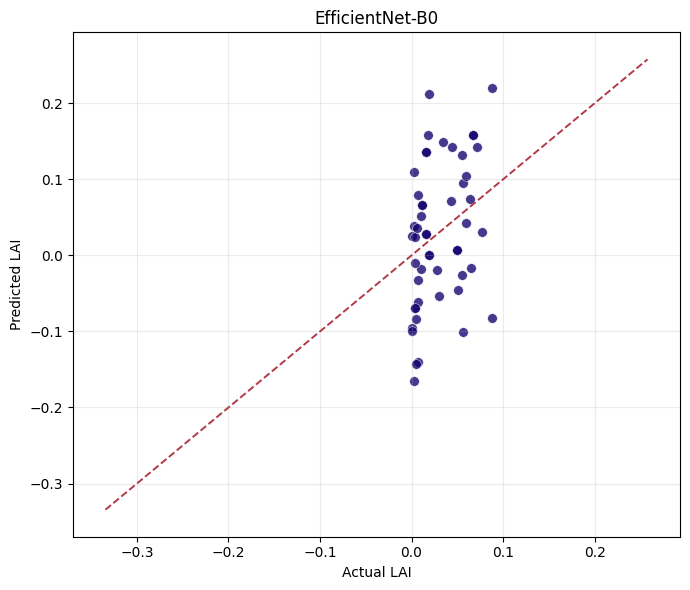

In [8]:
all_lai_values = [aligned[column].to_numpy() for column in aligned.columns if column.startswith(('actual_LAI_', 'predicted_LAI_'))]
axis_min = min(float(np.concatenate(all_lai_values).min()), 0.0)
axis_max = float(np.concatenate(all_lai_values).max())
padding = max((axis_max - axis_min) * 0.06, 0.01)

output_names = {
    'Random Forest': 'lai_random_forest_actual_vs_predicted.png',
    'ResNet-18': 'lai_resnet18_actual_vs_predicted.png',
    'EfficientNet-B0': 'lai_efficientnet_b0_actual_vs_predicted.png',
}

for model_name in prediction_files:
    actual = aligned['actual_LAI_' + model_name]
    predicted = aligned['predicted_LAI_' + model_name]
    figure, axis = plt.subplots(figsize=(7, 6))
    axis.scatter(actual, predicted, color="#12006d", alpha=0.78, edgecolor='white', linewidth=0.4, s=48)
    axis.plot([axis_min, axis_max], [axis_min, axis_max], linestyle='--', color='#b23a48', linewidth=1.4)
    axis.set_title(model_name)
    axis.set_xlabel('Actual LAI')
    axis.set_ylabel('Predicted LAI')
    axis.grid(alpha=0.25)
    axis.set_xlim(axis_min - padding, axis_max + padding)
    axis.set_ylim(axis_min - padding, axis_max + padding)
    figure.tight_layout()
    figure.savefig(results_dir / output_names[model_name], dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(figure)

## 5. Descriptive error analysis

Errors are defined as `predicted_LAI - actual_LAI`. These statistics describe the saved clean predictions only; no tuning or additional evaluation procedure is performed.

In [10]:
summary_rows = []
for model_name in prediction_files:
    actual = aligned['actual_LAI_' + model_name].to_numpy(dtype=float)
    predicted = aligned['predicted_LAI_' + model_name].to_numpy(dtype=float)
    error = predicted - actual
    summary_rows.append({
        'Model': model_name,
        'MAE': float(np.mean(np.abs(error))),
        'RMSE': float(np.sqrt(np.mean(error ** 2))),
        'R2': float(1 - np.sum(error ** 2) / np.sum((actual - actual.mean()) ** 2)),
        'mean_prediction_error': float(error.mean()),
        'std_prediction_error': float(error.std(ddof=1)),
        'minimum_prediction': float(predicted.min()),
        'maximum_prediction': float(predicted.max()),
    })
error_summary = pd.DataFrame(summary_rows)
display(error_summary.style.format({column: '{:.9f}' for column in error_summary.columns if column != 'Model'}))

,Model,MAE,RMSE,R2,mean_prediction_error,std_prediction_error,minimum_prediction,maximum_prediction
0,Random Forest,0.006192920,0.009753515,0.865564843,0.003529709,0.009182900,0.001877397,0.101295889
1,ResNet-18,0.096753566,0.120569790,-19.543174905,-0.039741542,0.114964507,-0.334434479,0.257721394
2,EfficientNet-B0,0.074103718,0.087935380,-9.927425230,-0.002105238,0.088784926,-0.164922684,0.220503822


## 6. Final model determination and interpretation

Random Forest used nine simple RGB-derived statistical features, while ResNet-18 and EfficientNet-B0 performed direct image-based regression. For this dataset and available sample size, the engineered RGB statistical representation was substantially more effective than the evaluated end-to-end CNN regression approaches. Dataset size, dataset characteristics, target distribution, and model configuration can all affect deep-learning performance; this result does not imply that CNNs are inherently unsuitable for LAI estimation.

An earlier Random Forest evaluation used a split containing identical image contents across different splits, so it was rejected as the final benchmark. The leakage-free split was verified with zero cross-split identical image hashes and zero cross-split duplicate paths. All final comparisons in this notebook use that clean split.

In [12]:
comparison_output = metric_table[['Model', 'MAE', 'RMSE', 'R2']].copy()
comparison_output.to_csv(results_dir / 'lai_model_comparison.csv', index=False)

best_model = comparison_output.sort_values(['MAE', 'RMSE', 'R2'], ascending=[True, True, False]).iloc[0]['Model']
rf = metrics['Random Forest']
print('FINAL LAI MODEL COMPARISON')
print()
for model_name in ('Random Forest', 'ResNet-18', 'EfficientNet-B0'):
    record = metrics[model_name]
    print(f'{model_name}:')
    print(f"MAE = {record['MAE']:.9f}")
    print(f"RMSE = {record['RMSE']:.9f}")
    print(f"R² = {record['R2']:.9f}")
    print()
print(f'BEST MODEL: {best_model}')
print('Random Forest has the lowest MAE, lowest RMSE, and highest R² (0.865565).')
print('Both CNN models produced negative R² values on the clean test set.')
print('Random Forest performed best among the three evaluated models on this dataset and experimental setup.')
print()
print('The final LAI model comparison is complete. No further LAI model training is required at this stage.')

FINAL LAI MODEL COMPARISON

Random Forest:
MAE = 0.006192920
RMSE = 0.009753515
R² = 0.865564843

ResNet-18:
MAE = 0.096753566
RMSE = 0.120569790
R² = -19.543174905

EfficientNet-B0:
MAE = 0.074103718
RMSE = 0.087935380
R² = -9.927425230

BEST MODEL: Random Forest
Random Forest has the lowest MAE, lowest RMSE, and highest R² (0.865565).
Both CNN models produced negative R² values on the clean test set.
Random Forest performed best among the three evaluated models on this dataset and experimental setup.

The final LAI model comparison is complete. No further LAI model training is required at this stage.
